   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 78.8 MB/s eta 0:00:00


Saving ys.webp to ys.webp


<ipython-input-5-831a75345f88>:23: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  self.model = MobileNetV2(weights='imagenet', include_top=False, pooling='avg')


Model loaded successfully
Analyzing image: ys.webp


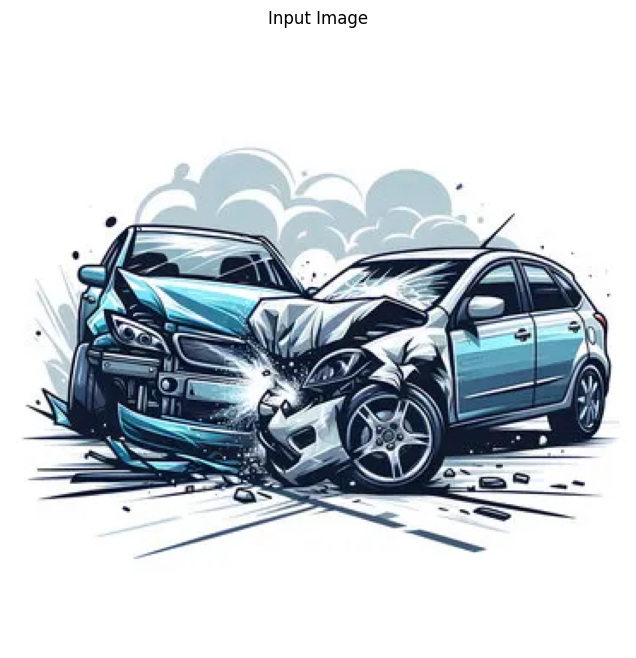

EXIF data found:
Orientation: 1
YCbCrPositioning: 1
ResolutionUnit: 2
ExifOffset: 102
XResolution: 72.0
YResolution: 72.0
ExifVersion: b'0210'
ComponentsConfiguration: b'\x01\x02\x03\x00'
FlashPixVersion: b'0100'
ColorSpace: 65535
ExifImageWidth: 360
ExifImageHeight: 360
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step

=== Image Verification Results ===
Is original: False

Detailed results:
From internet/AI-generated: True

=== Detailed Analysis ===

Internet check: Image shows signs of internet compression and possible watermarks (score: 916.97)

Metadata check: No creation date found in EXIF data

AI detection: Image appears to be naturally captured (score: 0.20)
Technical details:
  feature_std: 0.557044
  feature_mean: 0.384512
  feature_max: 3.118195
  laplacian_var: 1203.445110
  edge_density: 0.100559
  noise_level: 0.032194


In [ ]:
mport os
import requests
import time
import io
from google.colab import files
from datetime import datetime
from PIL import Image
from PIL.ExifTags import TAGS
import imagehash
import numpy as np
import cv2
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2, ResNet50
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
import matplotlib.pyplot as plt

class TrafficImageVerifier:
    def __init__(self):
        self.current_date = datetime.now()
        # Load pre-trained model for feature extraction
        # Using MobileNetV2 as it's lightweight and works well for feature extraction
        self.model = MobileNetV2(weights='imagenet', include_top=False, pooling='avg')
        print("Model loaded successfully")

    def verify_image(self, image_path):
        """Main function to verify if an image is original"""
        results = {
            "is_from_internet": False,
            "is_ai_generated": False,
            "is_old_image": False,
            "overall_score": 0.0,
            "details": {}
        }

        # Check if image exists (basic check)
        if not os.path.exists(image_path):
            return {"error": "Image file not found"}

        # Display the image
        self.display_image(image_path)

        # 1. Perform simple reverse image search simulation
        # In Kaggle, we'll use a basic approach since we don't have API access
        internet_check = self.check_image_artifacts(image_path)
        results["is_from_internet"] = internet_check["exists_online"]
        results["details"]["internet_check"] = internet_check

        # 2. Check EXIF metadata for timestamp
        metadata_check = self.analyze_exif_metadata(image_path)
        results["is_old_image"] = metadata_check["is_old_image"]
        results["details"]["metadata_check"] = metadata_check

        # 3. Check if image might be AI-generated
        ai_check = self.detect_ai_generated(image_path)
        results["is_ai_generated"] = ai_check["is_ai_generated"]
        results["details"]["ai_check"] = ai_check

        # Calculate overall score
        # Lower score means more likely to be original
        results["overall_score"] = (
            (1 if results["is_from_internet"] else 0) +
            (1 if results["is_ai_generated"] else 0) +
            (1 if results["is_old_image"] else 0)
        ) / 3.0

        # IMPORTANT CHANGE: If any major check fails, the image is not original
        # This ensures that if the image is from the internet, it's automatically not original
        results["is_original"] = not (results["is_from_internet"] or results["is_ai_generated"] or results["is_old_image"])

        return results

    def display_image(self, image_path):
        """Display the image in the notebook"""
        img = Image.open(image_path)
        plt.figure(figsize=(10, 8))
        plt.imshow(img)
        plt.title("Input Image")
        plt.axis('off')
        plt.show()

    def check_image_artifacts(self, image_path):
        """Check for common artifacts in images that might indicate it's from the internet"""
        result = {
            "exists_online": False,
            "confidence": 0.0,
            "message": ""
        }

        try:
            img = Image.open(image_path)
            img_array = np.array(img)

            # 1. Check for compression artifacts (typical of internet images)
            if len(img_array.shape) == 3:  # Color image
                # Convert to YCbCr and check for compression blocks
                img_ycbcr = img.convert('YCbCr')
                y_channel = np.array(img_ycbcr.getchannel(0))

                # Calculate the variance of the Y channel
                horizontal_var = np.var(np.diff(y_channel, axis=1))
                vertical_var = np.var(np.diff(y_channel, axis=0))

                # High variance in difference can indicate compression blocks
                compression_score = (horizontal_var + vertical_var) / 255.0

                # 2. Check for watermarks (using simple variance in regions)
                regions = 4
                h, w = y_channel.shape
                region_h, region_w = h // regions, w // regions

                region_variances = []
                for i in range(regions):
                    for j in range(regions):
                        region = y_channel[i*region_h:(i+1)*region_h, j*region_w:(j+1)*region_w]
                        region_variances.append(np.var(region))

                # High variance in variance across regions can indicate watermarks
                watermark_score = np.var(region_variances) / np.mean(region_variances) if np.mean(region_variances) > 0 else 0

                # Combine scores
                combined_score = 0.7 * compression_score + 0.3 * watermark_score
                result["confidence"] = min(1.0, combined_score)

                if combined_score > 0.6:
                    result["exists_online"] = True
                    result["message"] = f"Image shows signs of internet compression and possible watermarks (score: {combined_score:.2f})"
                else:
                    result["message"] = f"Image appears to be original (artifacts score: {combined_score:.2f})"

        except Exception as e:
            result["message"] = f"Error checking image artifacts: {str(e)}"

        return result

    def analyze_exif_metadata(self, image_path):
        """Analyze EXIF metadata for timestamp information"""
        result = {
            "has_exif": False,
            "is_old_image": False,
            "creation_date": None,
            "days_old": None,
            "message": ""
        }

        try:
            img = Image.open(image_path)

            # Check if image has EXIF data
            if hasattr(img, '_getexif') and img._getexif():
                exif_data = img._getexif()
                result["has_exif"] = True

                # Print all EXIF data for debugging
                print("EXIF data found:")
                for tag_id, value in exif_data.items():
                    tag = TAGS.get(tag_id, tag_id)
                    print(f"{tag}: {value}")

                # Extract DateTime or DateTimeOriginal
                date_time = None
                for tag_id, value in exif_data.items():
                    tag = TAGS.get(tag_id, tag_id)
                    if tag == "DateTime" or tag == "DateTimeOriginal":
                        date_time = value
                        break

                if date_time:
                    # Parse the date (format is typically "YYYY:MM:DD HH:MM:SS")
                    try:
                        creation_date = datetime.strptime(date_time, "%Y:%m:%d %H:%M:%S")
                        result["creation_date"] = creation_date.strftime("%Y-%m-%d %H:%M:%S")

                        # Calculate how old the image is
                        days_old = (self.current_date - creation_date).days
                        result["days_old"] = days_old

                        # If image is older than 1 day, consider it "old"
                        # You can adjust this threshold as needed
                        if days_old > 1:
                            result["is_old_image"] = True
                            result["message"] = f"Image is {days_old} days old"
                        else:
                            result["message"] = "Image appears to be recent"
                    except ValueError:
                        result["message"] = f"Found date format but couldn't parse: {date_time}"
                else:
                    result["message"] = "No creation date found in EXIF data"
            else:
                result["message"] = "No EXIF metadata found"

        except Exception as e:
            result["message"] = f"Error analyzing metadata: {str(e)}"

        return result

    def detect_ai_generated(self, image_path):
        """Detect if the image might be AI-generated using pre-trained model features"""
        result = {
            "is_ai_generated": False,
            "confidence": 0.0,
            "details": {},
            "message": ""
        }

        try:
            # Load image
            img = cv2.imread(image_path)
            if img is None:
                result["message"] = "Failed to load image for AI detection"
                return result

            # Approach 1: Deep Learning Feature Analysis
            # Extract features using pre-trained model
            img_tensor = self.preprocess_for_model(image_path)
            features = self.model.predict(img_tensor)

            # Analyze features
            # AI-generated images often have different feature distributions
            feature_std = np.std(features)
            feature_mean = np.mean(features)
            feature_max = np.max(features)

            # Approach 2: Traditional Image Analysis
            # Resize for consistent processing
            img_resized = cv2.resize(img, (512, 512))

            # Convert to grayscale for analysis
            gray = cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY)

            # Check for unnatural smoothness
            laplacian_var = cv2.Laplacian(gray, cv2.CV_64F).var()

            # Check for unusual edge patterns
            edges = cv2.Canny(gray, 100, 200)
            edge_density = np.count_nonzero(edges) / (512 * 512)

            # Check for noise patterns
            noise_level = self.estimate_noise(gray)

            # Combine metrics
            result["details"] = {
                "feature_std": float(feature_std),
                "feature_mean": float(feature_mean),
                "feature_max": float(feature_max),
                "laplacian_var": float(laplacian_var),
                "edge_density": float(edge_density),
                "noise_level": float(noise_level)
            }

            # Heuristic to combine metrics
            # These thresholds are estimates and may need tuning
            ai_score = 0.0

            if feature_std < 0.1:  # Unusually consistent features
                ai_score += 0.3

            if laplacian_var < 50:  # Too smooth
                ai_score += 0.2

            if edge_density < 0.01 or edge_density > 0.1:  # Unusual edge patterns
                ai_score += 0.2

            if noise_level < 0.005:  # Too little noise
                ai_score += 0.3

            result["confidence"] = ai_score
            result["is_ai_generated"] = ai_score > 0.5

            if result["is_ai_generated"]:
                result["message"] = f"Image shows characteristics of AI generation (score: {ai_score:.2f})"
            else:
                result["message"] = f"Image appears to be naturally captured (score: {ai_score:.2f})"

        except Exception as e:
            result["message"] = f"Error in AI detection: {str(e)}"

        return result

    def preprocess_for_model(self, image_path):
        """Preprocess image for the pre-trained model"""
        img = image.load_img(image_path, target_size=(224, 224))
        img_array = image.img_to_array(img)
        img_array = np.expand_dims(img_array, axis=0)
        img_array = preprocess_input(img_array)
        return img_array

    def estimate_noise(self, img):
        """Estimate noise level in an image"""
        # Method: Calculate standard deviation in uniform regions

        # Convert to float for calculations
        img_float = img.astype(np.float32) / 255.0

        # Apply median filter to get a "clean" version
        img_filtered = cv2.medianBlur(img_float, 3)

        # Calculate noise as difference between original and filtered
        noise = img_float - img_filtered

        # Return standard deviation of noise
        return np.std(noise)

# Function to run the verification
def run_verification(image_path):
    verifier = TrafficImageVerifier()
    print(f"Analyzing image: {image_path}")

    results = verifier.verify_image(image_path)

    print("\n=== Image Verification Results ===")
    print(f"Is original: {results.get('is_original', 'Unknown')}")
    print("\nDetailed results:")
    print(f"From internet/AI-generated: {results.get('is_from_internet', False)}")

    # Print details if available
    if "details" in results:
        print("\n=== Detailed Analysis ===")
        details = results["details"]

        if "internet_check" in details:
            print(f"\nInternet check: {details['internet_check']['message']}")

        if "metadata_check" in details:
            meta = details["metadata_check"]
            print(f"\nMetadata check: {meta['message']}")
            if meta.get("creation_date"):
                print(f"Creation date: {meta['creation_date']}")
            if meta.get("days_old") is not None:
                print(f"Days old: {meta['days_old']}")

        if "ai_check" in details:
            print(f"\nAI detection: {details['ai_check']['message']}")
            if "details" in details["ai_check"]:
                print("Technical details:")
                for key, value in details["ai_check"]["details"].items():
                    print(f"  {key}: {value:.6f}")

    return results

# Example usage
if __name__ == "__main__":
    # Replace with your image path
    uploaded = files.upload()
    image_path = list(uploaded.keys())[0]
    run_verification(image_path)